# 2. The torus
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sap6/MFS/blob/main/notebooks/2_torus.ipynb)

**Notebooks:** [1. Sphere](1_sphere.ipynb) · **2. Torus** · [3. Cube](3_cube.ipynb) · [4. NASA almond](4_almond.ipynb)

The torus $(\sqrt{x^2+y^2} - R)^2 + z^2 = a^2$ with $R = 1$, $a = 0.5$ is non-convex, has no closed-form solution, and is the first shape where the source surface is restricted from below (Sections 3.2 and 3.3 of the paper). Both the source rings (minor radius $a_s < a$) and boundary rings are invariant under discrete rotation about the $z$-axis, so a discrete Fourier transform decouples the system into $n_\varphi$ small $4n_s \times 3n_s$ least-squares problems (`mfs/torus.py`).

In [1]:
# Set up paths (and get the code and the data when run on Colab)
import os, subprocess, sys
if "google.colab" in sys.modules:
    if not os.path.exists("/content/MFS"):
        subprocess.run(["git", "clone", "-q", "https://github.com/sap6/MFS", "/content/MFS"], check=True)
    os.chdir("/content/MFS/notebooks")            # numpy, scipy, numba and matplotlib come with Colab
elif os.path.isdir("notebooks") and os.path.isdir("mfs"):
    os.chdir("notebooks")
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from mfs import core, torus

k = 2 * np.pi
d, p = core.wave()             # axial wave along -z, polarised along y
pts = 2.5 * core.sphere_rule(10, 20)[0]

## Azimuthal decoupling and convergence
An axial plane wave excites only the two azimuthal Fourier modes $m = \pm 1$ ($2 \times 3n_s$ solved unknowns), whereas an oblique wave excites every mode up to $|m| \approx k(R + a)$, yet both decouple into the same independent $4n_s \times 3n_s$ blocks. We check convergence against a finer MFS run and verify energy conservation via the optical theorem.

In [3]:
ref = torus.scatter(k, d, p, 44, 160)           # 44 rings of 160 dipoles: 21120 total unknowns (264 solved for axial wave)
E_ref = ref.field(pts)
for ns, nphi in ((8, 28), (12, 40), (16, 52), (20, 64), (28, 96)):
    s = torus.scatter(k, d, p, ns, nphi)
    optical = torus.optical(s, d, p)[1]
    print(f"{3 * ns * nphi:6d} total ({6 * ns:3d} solved) unknowns: diff {core.rel(s.field(pts), E_ref):.1e}, "
          f"optical mismatch {optical:.1e}")

# Oblique incidence (polar 60 deg, azimuth 25 deg, polarisation 35 deg)
d_obl, p_obl = core.wave(60, 25, 35)
s_obl = torus.scatter(k, d_obl, p_obl, 36, 128)
ah_norms = np.linalg.norm(np.fft.fft(s_obl.alpha.reshape(36, 128, 3), axis=1), axis=(0, 2))
n_excited = int(np.sum(ah_norms > 1e-12 * ah_norms.max()))
print(f"\nOblique wave (13824 unknowns): {n_excited} excited Fourier modes, "
      f"boundary residual {torus.residual(s_obl, d_obl, p_obl):.1e}, optical mismatch {torus.optical(s_obl, d_obl, p_obl)[1]:.1e}")

   672 total ( 48 solved) unknowns: diff 9.3e-02, optical mismatch 8.6e-03
  1440 total ( 72 solved) unknowns: diff 5.0e-03, optical mismatch 1.9e-03


  2496 total ( 96 solved) unknowns: diff 7.6e-04, optical mismatch 3.6e-04


  3840 total (120 solved) unknowns: diff 1.1e-04, optical mismatch 5.5e-05


  8064 total (168 solved) unknowns: diff 5.0e-07, optical mismatch 2.7e-07



Oblique wave (13824 unknowns): 59 excited Fourier modes, boundary residual 8.7e-09, optical mismatch 4.8e-10


## How thin may the source torus be?
In toroidal coordinates, the focal ring lies at radius $\sqrt{R^2 - a^2}$ in the plane $z = 0$. To enclose it on the inner side ($R - a_s < \sqrt{R^2 - a^2}$), a concentric source torus must satisfy
$$a_s > R - \sqrt{R^2 - a^2}.$$
For $R = 1$, $a = 0.8$, this bound is $a_s / a = 0.5$: as soon as the source circle shrinks inside the focal ring, the coefficient norm $\|\boldsymbol{\alpha}\|$ jumps by orders of magnitude and accuracy is lost (Figure 2 of the paper).

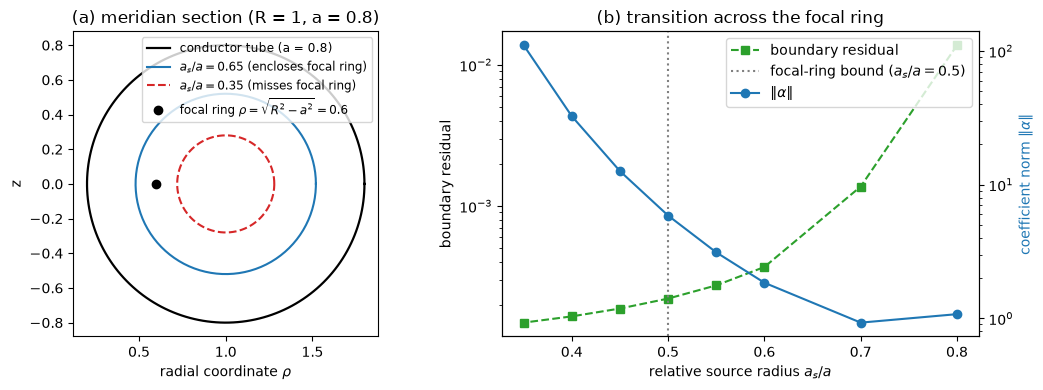

In [4]:
a = 0.8
bound = (1 - np.sqrt(1 - a ** 2)) / a           # 0.5 for a / R = 0.8
fracs = (0.8, 0.7, 0.6, 0.55, 0.5, 0.45, 0.4, 0.35)
sols = [torus.scatter(k, d, p, 24, 96, a=a, a_s=f * a, rings=3) for f in fracs]
norms = [np.linalg.norm(s.alpha) for s in sols]
resids = [torus.residual(s, d, p) for s in sols]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
th = np.linspace(0, 2 * np.pi, 200)
ax1.plot(1 + a * np.cos(th), a * np.sin(th), "k-", lw=1.6, label="conductor tube (a = 0.8)")
ax1.plot(1 + 0.65 * a * np.cos(th), 0.65 * a * np.sin(th), "-", color="tab:blue", label="$a_s/a = 0.65$ (encloses focal ring)")
ax1.plot(1 + 0.35 * a * np.cos(th), 0.35 * a * np.sin(th), "--", color="tab:red", label="$a_s/a = 0.35$ (misses focal ring)")
ax1.plot([np.sqrt(1 - a ** 2)], [0.0], "ko", ms=6, label=r"focal ring $\rho = \sqrt{R^2-a^2} = 0.6$")
ax1.set(aspect="equal", xlabel=r"radial coordinate $\rho$", ylabel="z", title="(a) meridian section (R = 1, a = 0.8)")
ax1.legend(fontsize=8.5, loc="upper right")

ax2.semilogy(fracs, resids, "s--", color="tab:green", label="boundary residual")
ax2.axvline(bound, ls=":", color="grey", label=f"focal-ring bound ($a_s/a = {bound:.1f}$)")
ax2r = ax2.twinx()
ax2r.semilogy(fracs, norms, "o-", color="tab:blue", label=r"$\|\alpha\|$")
ax2.set(xlabel="relative source radius $a_s / a$", ylabel="boundary residual", title="(b) transition across the focal ring")
ax2r.set_ylabel(r"coefficient norm $\|\alpha\|$", color="tab:blue")
h1, l1 = ax2.get_legend_handles_labels(); h2, l2 = ax2r.get_legend_handles_labels()
ax2.legend(h1 + h2, l1 + l2, loc="upper right")
fig.tight_layout()
plt.show()